In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import models
import keras.datasets as kds


import numpy as np
import matplotlib.pyplot as plt
from matplotlib.image import imread

print(tf.__version__)

2.21.0


In [ ]:
num_classes = 10
input_shape = (28, 28, 1)

#Carga de dados dataset ketas
(x_train, y_train), (x_test, y_test) = kds.mnist.load_data()

#normalizar feat
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

#conersao classes one-hot-encoding
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


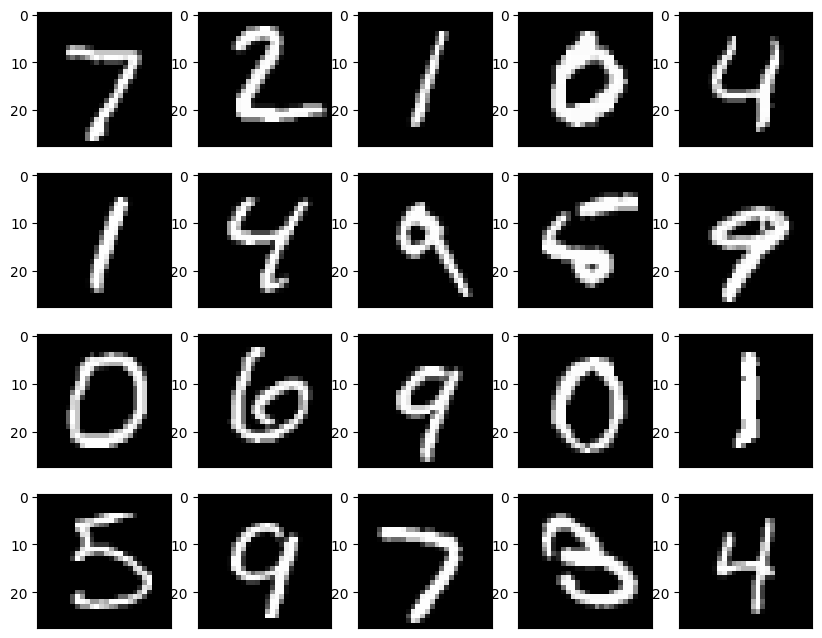

In [ ]:
plt.figure(figsize=(10,8))
for i in range (20):
  ax = plt.subplot(4,5,i+1)
  plt.imshow(x_test[i].reshape(28,28))
  plt.gray()
  ax.get_xaxis().set_visible(False)
  ax.get_xaxis().set_visible(False)
plt.show()

**Rede - MCP**

In [ ]:
modelo1 = keras.Sequential()
modelo1.add(keras.layers.Flatten(input_shape=input_shape))
modelo1.add(keras.layers.Dense(units=10, activation="softmax"))

modelo1.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

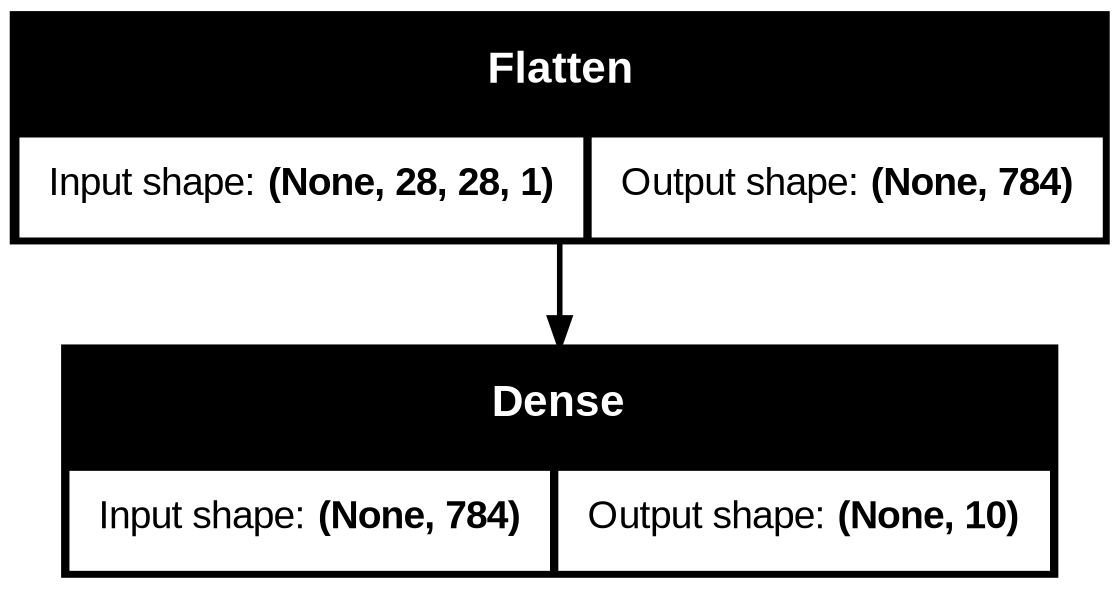

In [ ]:
#Grafo da rede
tf.keras.utils.plot_model(modelo1, show_shapes=True)

In [ ]:
modelo1.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

#treinamento
history = modelo1.fit(x_train, y_train, batch_size=256, epochs=30, verbose=2, validation_split=0.2)

Epoch 1/30
188/188 - 4s - 23ms/step - accuracy: 0.7694 - loss: 0.9459 - val_accuracy: 0.8817 - val_loss: 0.5077
Epoch 2/30
188/188 - 1s - 4ms/step - accuracy: 0.8819 - loss: 0.4679 - val_accuracy: 0.9019 - val_loss: 0.3878
Epoch 3/30
188/188 - 1s - 4ms/step - accuracy: 0.8966 - loss: 0.3887 - val_accuracy: 0.9082 - val_loss: 0.3451
Epoch 4/30
188/188 - 1s - 4ms/step - accuracy: 0.9040 - loss: 0.3524 - val_accuracy: 0.9138 - val_loss: 0.3220
Epoch 5/30
188/188 - 1s - 4ms/step - accuracy: 0.9094 - loss: 0.3308 - val_accuracy: 0.9174 - val_loss: 0.3077
Epoch 6/30
188/188 - 1s - 4ms/step - accuracy: 0.9133 - loss: 0.3163 - val_accuracy: 0.9195 - val_loss: 0.2959
Epoch 7/30
188/188 - 1s - 4ms/step - accuracy: 0.9150 - loss: 0.3058 - val_accuracy: 0.9207 - val_loss: 0.2899
Epoch 8/30
188/188 - 1s - 7ms/step - accuracy: 0.9174 - loss: 0.2976 - val_accuracy: 0.9222 - val_loss: 0.2847
Epoch 9/30
188/188 - 1s - 4ms/step - accuracy: 0.9191 - loss: 0.2914 - val_accuracy: 0.9232 - val_loss: 0.2807


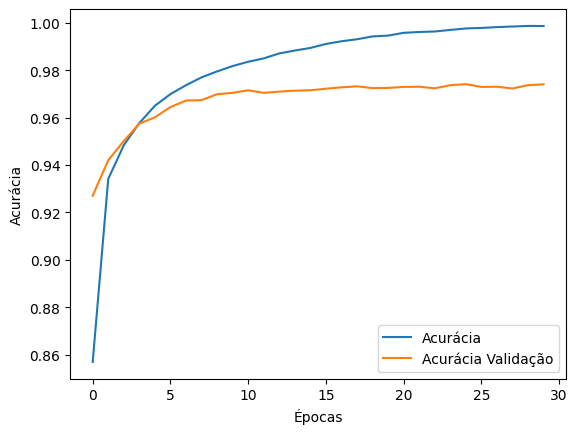

In [ ]:
plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.plot(history.history["accuracy"], label="Acurácia")
plt.plot(history.history["val_accuracy"], label="Acurácia Validação")
plt.legend()

In [ ]:
#Avaliação modelo de trinamento
print("AValiação do modelo de (teste)")
results = modelo1.evaluate(x_test, y_test, batch_size=256)
print("test loss, test acc:", results)

AValiação do modelo de (teste)
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9286 - loss: 0.2639
test loss, test acc: [0.26387709379196167, 0.928600013256073]


**Rede - MLP**

In [ ]:
modelo2 = keras.Sequential()
modelo2.add(keras.layers.Flatten(input_shape=input_shape))
modelo2.add(keras.layers.Dense(units=100, activation="relu"))
modelo2.add(keras.layers.Dense(units=10, activation="softmax"))

modelo2.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

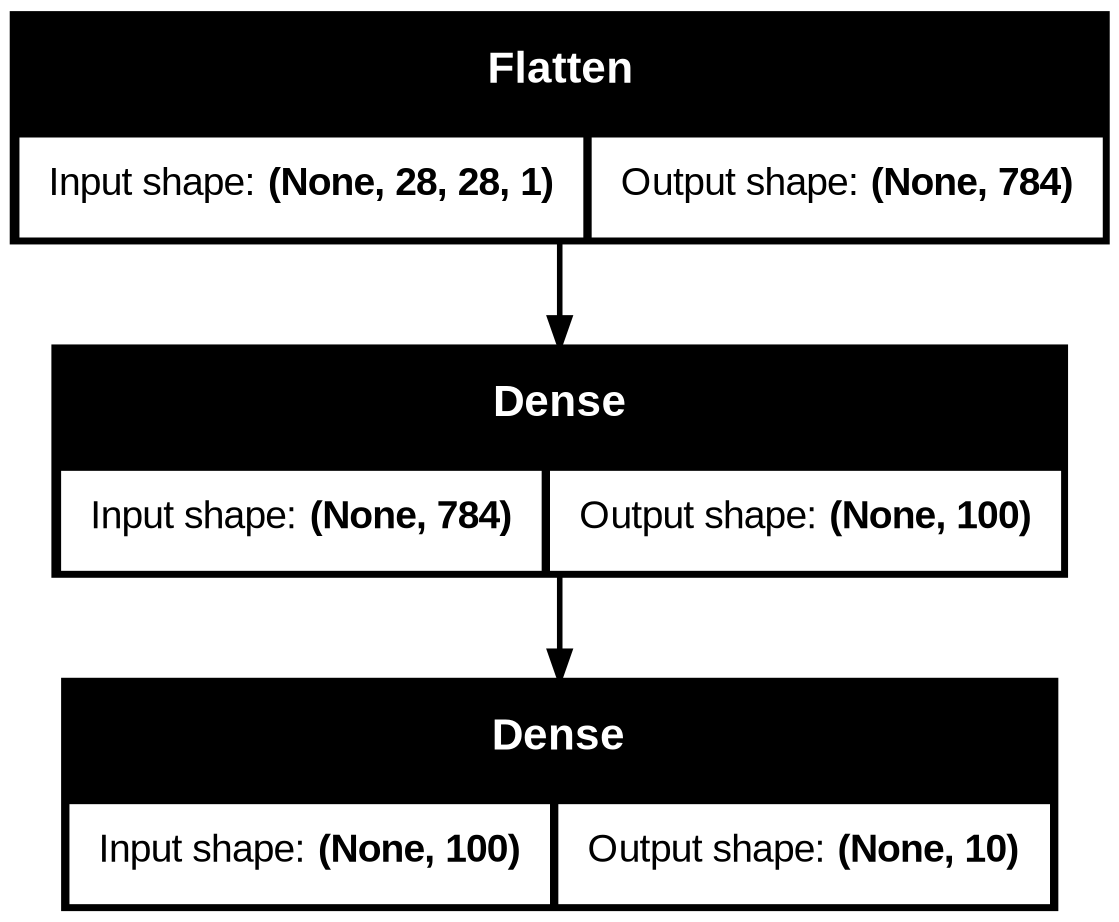

In [ ]:
#Grafo gerado
tf.keras.utils.plot_model(modelo2, show_shapes=True)

In [ ]:
modelo2.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

#treinamento
history = modelo2.fit(x_train, y_train, batch_size=256, epochs=30, verbose=2, validation_split=0.2)

Epoch 1/30
188/188 - 4s - 20ms/step - accuracy: 0.8569 - loss: 0.5277 - val_accuracy: 0.9271 - val_loss: 0.2621
Epoch 2/30
188/188 - 1s - 4ms/step - accuracy: 0.9342 - loss: 0.2393 - val_accuracy: 0.9421 - val_loss: 0.2093
Epoch 3/30
188/188 - 1s - 4ms/step - accuracy: 0.9484 - loss: 0.1837 - val_accuracy: 0.9502 - val_loss: 0.1718
Epoch 4/30
188/188 - 1s - 4ms/step - accuracy: 0.9578 - loss: 0.1500 - val_accuracy: 0.9575 - val_loss: 0.1513
Epoch 5/30
188/188 - 1s - 5ms/step - accuracy: 0.9651 - loss: 0.1263 - val_accuracy: 0.9602 - val_loss: 0.1385
Epoch 6/30
188/188 - 1s - 4ms/step - accuracy: 0.9700 - loss: 0.1088 - val_accuracy: 0.9645 - val_loss: 0.1219
Epoch 7/30
188/188 - 1s - 4ms/step - accuracy: 0.9737 - loss: 0.0947 - val_accuracy: 0.9672 - val_loss: 0.1147
Epoch 8/30
188/188 - 1s - 4ms/step - accuracy: 0.9770 - loss: 0.0838 - val_accuracy: 0.9674 - val_loss: 0.1089
Epoch 9/30
188/188 - 1s - 4ms/step - accuracy: 0.9795 - loss: 0.0748 - val_accuracy: 0.9699 - val_loss: 0.1056


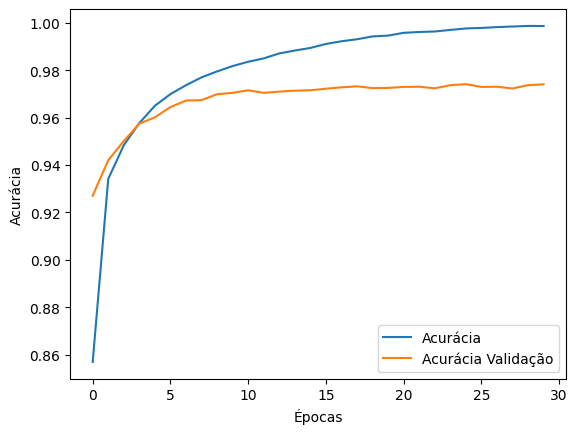

In [ ]:
plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.plot(history.history["accuracy"], label="Acurácia")
plt.plot(history.history["val_accuracy"], label="Acurácia Validação")
plt.legend()

In [ ]:
#Avaliação do modelo
print("AValiação do modelo de (teste)")
results = modelo2.evaluate(x_test, y_test, batch_size=256)
print("test loss, test acc:", results)

AValiação do modelo de (teste)
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9761 - loss: 0.0859
test loss, test acc: [0.08594558387994766, 0.9761000275611877]


**Rede - CNN**

In [ ]:
modelo3 = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        keras.layers.Conv2D(5, kernel_size=(3, 3), activation="relu"),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Conv2D(10, kernel_size=(3, 3), activation="relu"),
        keras.layers.MaxPooling2D(pool_size=(2, 2)),
        keras.layers.Flatten(),
        keras.layers.Dense(num_classes, activation="softmax"),
    ]
)

modelo3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 5)      │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 5)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 10)     │           460 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 10)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 250)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         2,510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,020 (11.80 KB)

 Trainable params: 3,020 (11.80 KB)

 Non-trainable params: 0 (0.00 B)

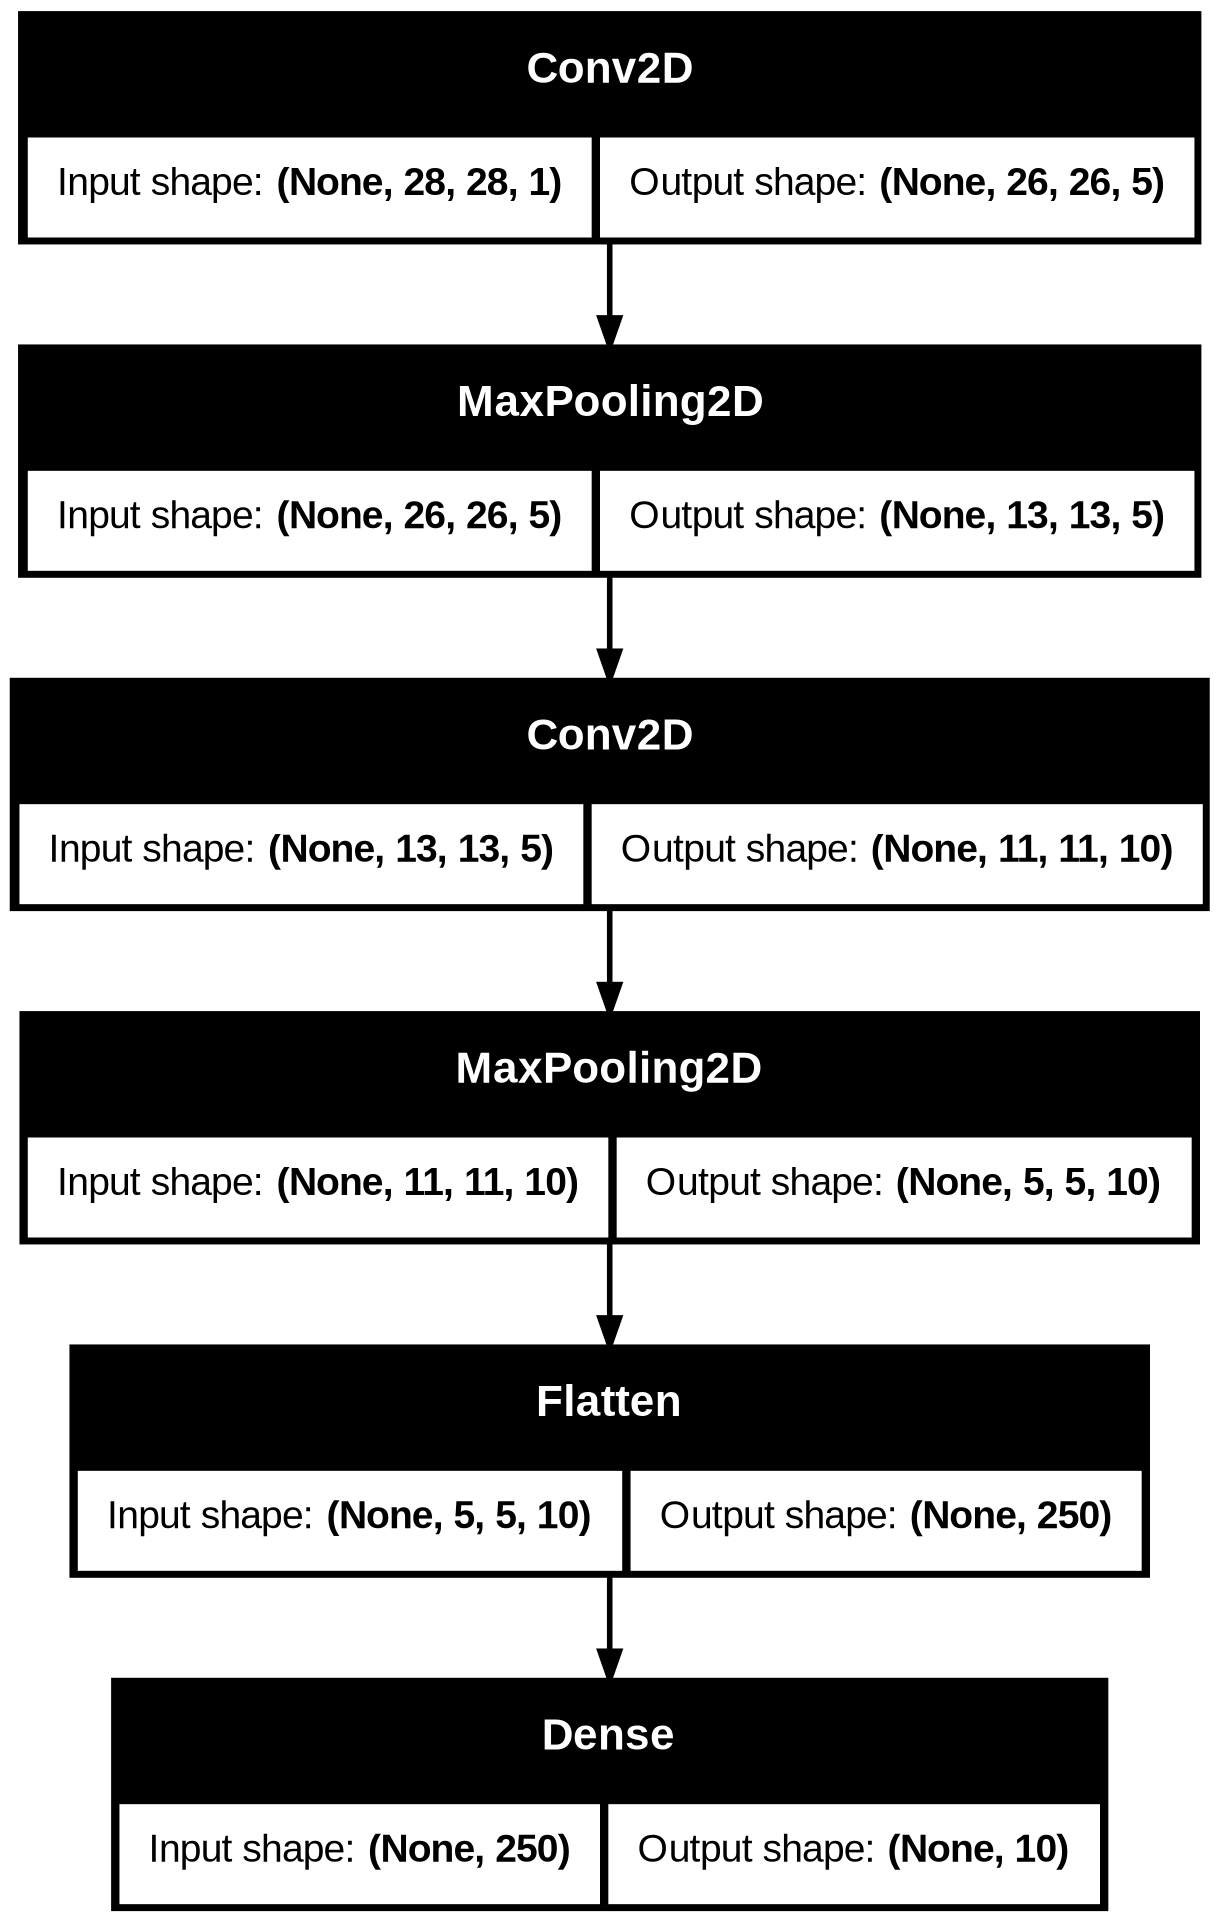

In [ ]:
tf.keras.utils.plot_model(modelo3, show_shapes=True)

In [ ]:
modelo3.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

#treinamento
history = modelo3.fit(x_train, y_train, batch_size=256, epochs=30, verbose=2, validation_split=0.2)

Epoch 1/30
188/188 - 9s - 48ms/step - accuracy: 0.7140 - loss: 1.0173 - val_accuracy: 0.9045 - val_loss: 0.3336
Epoch 2/30
188/188 - 1s - 5ms/step - accuracy: 0.9134 - loss: 0.2935 - val_accuracy: 0.9361 - val_loss: 0.2197
Epoch 3/30
188/188 - 1s - 5ms/step - accuracy: 0.9364 - loss: 0.2131 - val_accuracy: 0.9462 - val_loss: 0.1737
Epoch 4/30
188/188 - 1s - 5ms/step - accuracy: 0.9480 - loss: 0.1715 - val_accuracy: 0.9571 - val_loss: 0.1428
Epoch 5/30
188/188 - 1s - 5ms/step - accuracy: 0.9563 - loss: 0.1447 - val_accuracy: 0.9613 - val_loss: 0.1274
Epoch 6/30
188/188 - 1s - 5ms/step - accuracy: 0.9619 - loss: 0.1277 - val_accuracy: 0.9655 - val_loss: 0.1149
Epoch 7/30
188/188 - 1s - 5ms/step - accuracy: 0.9650 - loss: 0.1144 - val_accuracy: 0.9684 - val_loss: 0.1031
Epoch 8/30
188/188 - 1s - 5ms/step - accuracy: 0.9683 - loss: 0.1048 - val_accuracy: 0.9704 - val_loss: 0.0991
Epoch 9/30
188/188 - 1s - 5ms/step - accuracy: 0.9703 - loss: 0.0971 - val_accuracy: 0.9732 - val_loss: 0.0898


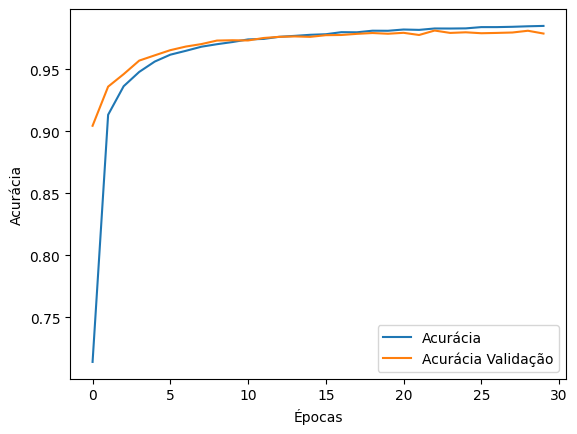

In [ ]:
plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.plot(history.history["accuracy"], label="Acurácia")
plt.plot(history.history["val_accuracy"], label="Acurácia Validação")
plt.legend()

plt.show()

In [ ]:
#Avaliação do modelo
print("AValiação do modelo de (teste)")
results = modelo3.evaluate(x_test, y_test, batch_size=256)
print("test loss, test acc:", results)

AValiação do modelo de (teste)
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9816 - loss: 0.0571
test loss, test acc: [0.05707617849111557, 0.9815999865531921]


**Modelo INCEPTION**

In [ ]:
from tensorflow.keras.applications.inception_v3 import InceptionV3

inception = InceptionV3(input_shape=(150, 150, 3), include_top=False, weights="imagenet")

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [ ]:
#Congelar camadas Ocultas, usar as bases ja treinadas
for layer in inception.layers:
  layer.trainable=False

In [ ]:
last_layer = inception.get_layer('mixed7')
print('Dimensões ultimas camadas de rede:', last_layer.output.shape)
last_output = last_layer.output

Dimensões ultimas camadas de rede: (None, 7, 7, 768)


In [ ]:
#Flattening  ultima camada CNN
x = layers.Flatten()(last_output)
#Camada com 512 neuronios
x = layers.Dense(512, activation='relu')(x)
# % de dados para trinamento
x = layers.Dropout(0.2)(x)
#Neuronio de saida
x = layers.Dense(1, activation='sigmoid')(x)

#Criação do modelo
modelo4 = models.Model(inception.input, x)

modelo4.compile(loss='binary_crossentropy',
              optimizer='adam',
              metrics=['acc'])



In [ ]:
for layer in modelo4.layers:
  print(layer.name, layer.trainable)

input_layer_4 False
conv2d_2 False
batch_normalization False
activation False
conv2d_3 False
batch_normalization_1 False
activation_1 False
conv2d_4 False
batch_normalization_2 False
activation_2 False
max_pooling2d_2 False
conv2d_5 False
batch_normalization_3 False
activation_3 False
conv2d_6 False
batch_normalization_4 False
activation_4 False
max_pooling2d_3 False
conv2d_10 False
batch_normalization_8 False
activation_8 False
conv2d_8 False
conv2d_11 False
batch_normalization_6 False
batch_normalization_9 False
activation_6 False
activation_9 False
average_pooling2d False
conv2d_7 False
conv2d_9 False
conv2d_12 False
conv2d_13 False
batch_normalization_5 False
batch_normalization_7 False
batch_normalization_10 False
batch_normalization_11 False
activation_5 False
activation_7 False
activation_10 False
activation_11 False
mixed0 False
conv2d_17 False
batch_normalization_15 False
activation_15 False
conv2d_15 False
conv2d_18 False
batch_normalization_13 False
batch_normalization_16 Fa

In [ ]:
tf.keras.utils.plot_model(modelo4, show_shapes=True)

In [ ]:
import tensorflow as tf

# Baixando de forma segura utilizando o utilitário nativo do TensorFlow
print("Iniciando o download do dataset...")
path_to_zip = tf.keras.utils.get_file(
    'cats_and_dogs_filtered.zip',
    origin='https://download.mlcc.google.com/mledu-datasets/cats_and_dogs_filtered.zip',
    extract=False,
    cache_dir='/tmp',
    cache_subdir=''
)

print("Download concluído e salvo em:", path_to_zip)

Iniciando o download do dataset...
68606236/68606236 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Download concluído e salvo em: /tmp/cats_and_dogs_filtered.zip


In [ ]:
import os
import zipfile

from tensorflow.keras.preprocessing.image import ImageDataGenerator

local_zip = '/tmp/cats_and_dogs_filtered.zip'
zip_ref = zipfile.ZipFile(local_zip, 'r')
zip_ref.extractall('/tmp')
zip_ref.close()


#Define arquivos e diretorios
base_dir = '/tmp/cats_and_dogs_filtered'
train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')

#Diretorio fotos gatos
train_cats_dir = os.path.join(train_dir, 'cats')

#Diretorio fotos cao
train_dogs_dir = os.path.join(train_dir, 'dogs')

#Diretorios para treinamento e validacao
validation_cats_dir = os.path.join(validation_dir, 'cats')
validation_dogs_dir = os.path.join(validation_dir, 'dogs')

train_cat_fnames = os.listdir(train_cats_dir)
train_dog_fnames = os.listdir(train_dogs_dir)

#ADD parametros e argumentos dos dados para ImageDataGenerator
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

#Validação não argumentada
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    batch_size=20,
    class_mode='binary',
    target_size=(150, 150)
)

#Validação da imagem em batching 20
validation_generator = val_datagen.flow_from_directory(
    validation_dir,
    batch_size=20,
    class_mode='binary',
    target_size=(150, 150)
)

Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.


In [ ]:
history = modelo4.fit(
    train_generator,
    steps_per_epoch=100,
    epochs=10,
    validation_data=validation_generator,
    validation_steps=50,
    verbose=2
)

Epoch 1/10
100/100 - 36s - 361ms/step - acc: 0.8785 - loss: 0.3988 - val_acc: 0.9410 - val_loss: 0.1640
Epoch 2/10
100/100 - 18s - 175ms/step - acc: 0.9030 - loss: 0.2254 - val_acc: 0.9640 - val_loss: 0.0919
Epoch 3/10
100/100 - 17s - 173ms/step - acc: 0.9280 - loss: 0.1843 - val_acc: 0.9650 - val_loss: 0.0885
Epoch 4/10
100/100 - 17s - 171ms/step - acc: 0.9240 - loss: 0.1829 - val_acc: 0.9600 - val_loss: 0.0911
Epoch 5/10
100/100 - 17s - 171ms/step - acc: 0.9310 - loss: 0.1725 - val_acc: 0.9630 - val_loss: 0.0987
Epoch 6/10
100/100 - 18s - 176ms/step - acc: 0.9425 - loss: 0.1518 - val_acc: 0.9670 - val_loss: 0.0886
Epoch 7/10
100/100 - 17s - 172ms/step - acc: 0.9405 - loss: 0.1443 - val_acc: 0.9710 - val_loss: 0.0858
Epoch 8/10
100/100 - 17s - 173ms/step - acc: 0.9335 - loss: 0.1499 - val_acc: 0.9690 - val_loss: 0.0806
Epoch 9/10
100/100 - 17s - 173ms/step - acc: 0.9550 - loss: 0.1192 - val_acc: 0.9550 - val_loss: 0.1186
Epoch 10/10
100/100 - 17s - 174ms/step - acc: 0.9465 - loss: 0.1

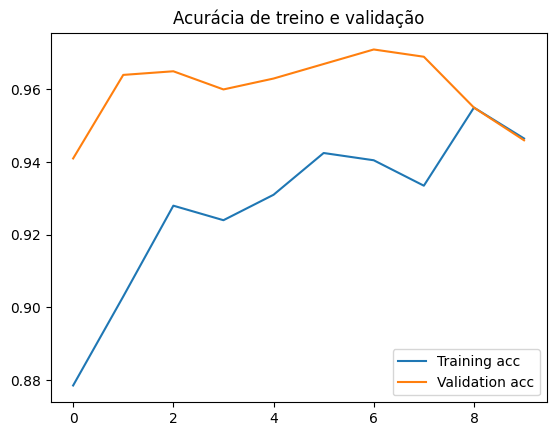

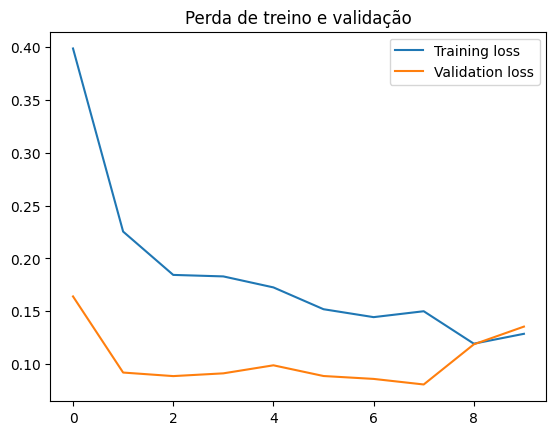

In [ ]:
acc = history.history['acc']
val_acc = history.history['val_acc']
loss = history.history['loss']
val_loss = history.history['val_loss']

#Num épocas
epochs = range(len(acc))

plt.plot(epochs, acc, label='Training acc')
plt.plot(epochs, val_acc, label='Validation acc')
plt.title('Acurácia de treino e validação')
plt.legend()

plt.figure()

plt.plot(epochs, loss, label='Training loss')
plt.plot(epochs, val_loss, label='Validation loss')
plt.title('Perda de treino e validação')
plt.legend()

plt.show()